In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

**1. QUESTION DE DÉPART**

Il faut identifier le besoin métier, le traduire en questions décisionnelles, puis examiner les sources disponibles pour vérifier si elles contiennent les informations nécessaires.

**2. COMMENT ALLEZ-VOUS RAISONNER ?**

- **Q1:** Nous devons comprendre les résultats des ventes afin d’identifier les tendances et d’aider à la prise de décision commerciale.
- **Q2:** Comment les ventes évoluent-elles au cours du temps? Quels produits sont les plus vendus? Quels pays contribuent le plus aux ventes?
- **Q3:** la vente de produits en ligne, observable à travers les informations relatives aux commandes, produits, quantités et clients.
- **Q4:** InvoiceDate, Quantity, UnitPrice, StockCode, Description, InvoiceNo, Country et CustomerID.
- **Q5:** La source peut contenir des valeurs manquantes et des informations limitées pour certaines analyses.
- **Q6:** En comparant l’inventaire avec les colonnes réellement présentes dans le fichier.

**MANIPULATION TECHNIQUE**   ***7.1 Charger et inspecter la source***

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

candidats = []
if Path("/kaggle/input").exists():
    candidats.extend(Path("/kaggle/input").rglob("*.xlsx"))
candidats.extend(Path(".").glob("*.xlsx"))
if Path("/mnt/data/Online Retail.xlsx").exists():
    candidats.append(Path("/mnt/data/Online Retail.xlsx"))

candidats = [p for p in candidats if "online retail" in p.name.lower()]
if not candidats:
    raise FileNotFoundError("Ajoutez Online Retail.xlsx au notebook Kaggle, puis relancez cette cellule.")

fichier = candidats[0]
print("Fichier utilisé :", fichier)

df = pd.read_excel(fichier)

print("Dimensions :", df.shape)
print("Colonnes :", df.columns.tolist())
display(df.head())

Fichier utilisé : /kaggle/input/datasets/nisrineqacem/online-retail-xslx/Online Retail.xlsx
Dimensions : (541909, 8)
Colonnes : ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


**Question d’analyse :**

Le fichier doit être vérifié à partir de ses colonnes et de ses premières lignes. Il ne faut pas inventer de champs qui ne sont pas présents.

***7.2 Profiler les champs utiles***

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [4]:
print("Valeurs manquantes par colonne :")
display(df.isna().sum().to_frame("Nombre de valeurs manquantes"))

Valeurs manquantes par colonne :


,Nombre de valeurs manquantes
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [5]:
display(df.describe(include="all"))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN


**Observation et interprétation**
Les résultats obtenus sur le fichier fourni sont les suivants :
- 541909 lignes et 8 colonnes.
- Les huit colonnes attendues sont présentes.
- `Description` contient 1454 valeurs manquantes.
- `CustomerID` contient 135080 valeurs manquantes.
- Les autres colonnes ne présentent pas de valeur manquante dans ce contrôle.
- Les dates vont du 1er décembre 2010 au 9 décembre 2011.

**Une valeur manquante est-elle automatiquement une erreur métier ?**  
Non. Un `CustomerID` manquant signifie que le client n’est pas identifié dans cette ligne, mais cela ne prouve pas à lui seul que la transaction est erronée. Une description manquante limite l’identification textuelle du produit, même si `StockCode` est disponible.

**8. Questions décisionnelles**

### Question 1 — Évolution dans le temps
**Question :** Comment le montant des transactions enregistrées évolue-t-il chaque mois ?  
**Champs :** `InvoiceDate`, `Quantity`, `UnitPrice`.  
**Mesure :** somme de `Quantity × UnitPrice`.

### Question 2 — Produits
**Question :** Quels produits présentent les montants de transaction enregistrés les plus élevés ?  
**Champs :** `StockCode`, `Description`, `Quantity`, `UnitPrice`.  
**Mesure :** somme de `Quantity × UnitPrice` par produit.

### Question 3 — Pays
**Question :** Quels pays présentent les montants de transaction enregistrés les plus élevés ?  
**Champs :** `Country`, `Quantity`, `UnitPrice`.  
**Mesure :** somme de `Quantity × UnitPrice` par pays.  

### Question 4 — Clients identifiés/inconnus
**Question :** Quelle part des lignes de transaction possède un identifiant client renseigné ou manquant ?  
**Champ :** `CustomerID`.  
**Mesure :** nombre de lignes avec identifiant renseigné ou manquant. 

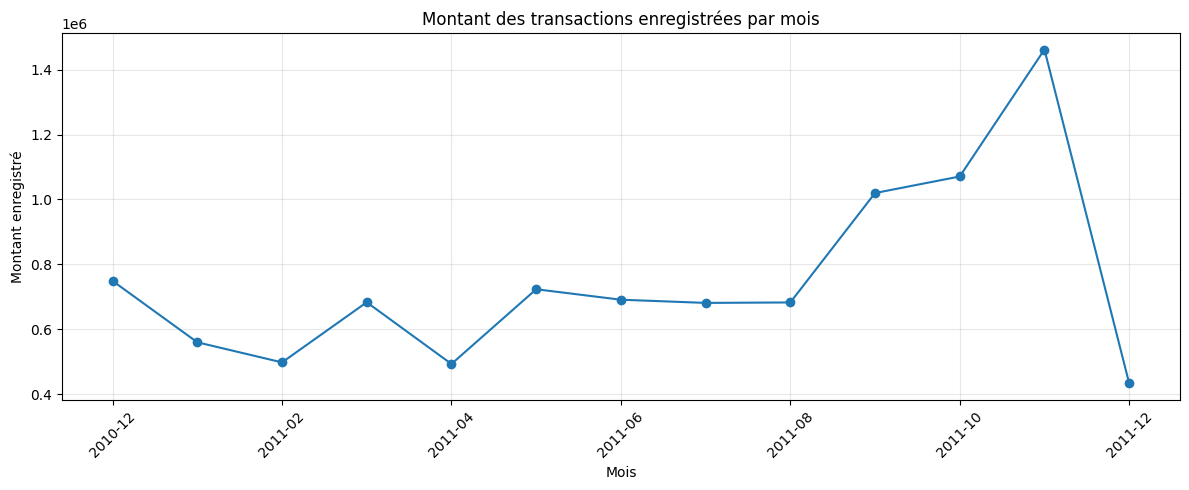

In [6]:
montant = df["Quantity"] * df["UnitPrice"]
serie_mensuelle = montant.groupby(df["InvoiceDate"].dt.to_period("M")).sum()
serie_mensuelle.index = serie_mensuelle.index.astype(str)

plt.figure(figsize=(12, 5))
serie_mensuelle.plot(kind="line", marker="o")
plt.title("Montant des transactions enregistrées par mois")
plt.xlabel("Mois")
plt.ylabel("Montant enregistré")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

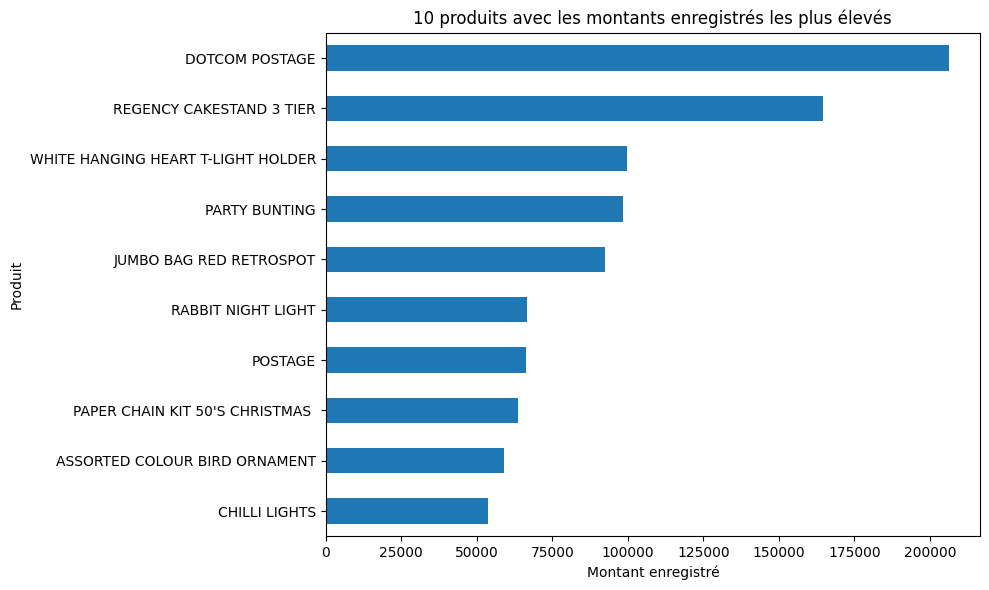

In [7]:
montant = df["Quantity"] * df["UnitPrice"]
montant_produit = montant.groupby(df["Description"].fillna("Description manquante")).sum()
top_produits = montant_produit.sort_values(ascending=False).head(10).sort_values()

plt.figure(figsize=(10, 6))
top_produits.plot(kind="barh")
plt.title("10 produits avec les montants enregistrés les plus élevés")
plt.xlabel("Montant enregistré")
plt.ylabel("Produit")
plt.tight_layout()
plt.show()

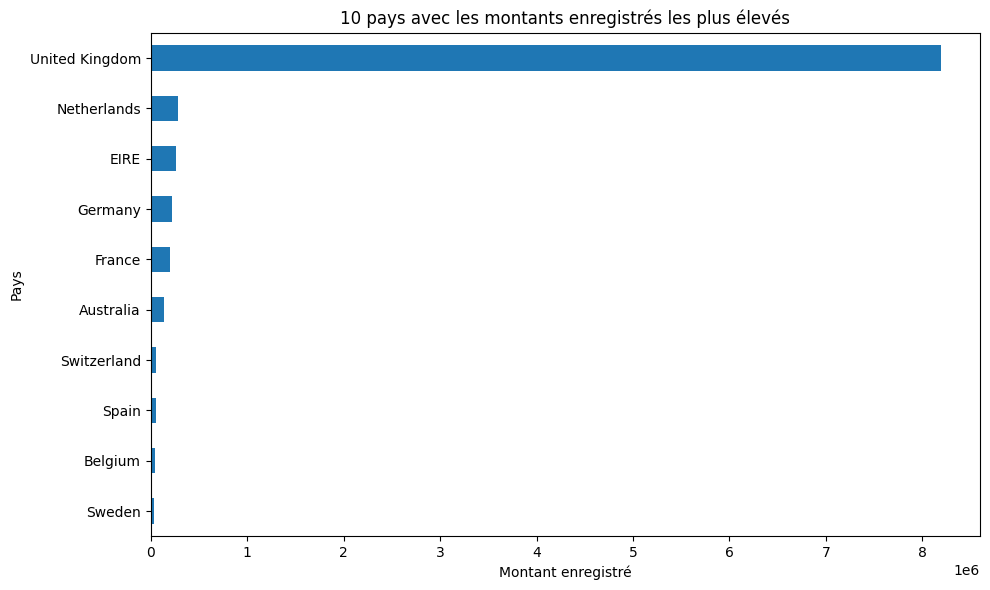

In [8]:
montant = df["Quantity"] * df["UnitPrice"]
montant_pays = montant.groupby(df["Country"]).sum()
top_pays = montant_pays.sort_values(ascending=False).head(10).sort_values()

plt.figure(figsize=(10, 6))
top_pays.plot(kind="barh")
plt.title("10 pays avec les montants enregistrés les plus élevés")
plt.xlabel("Montant enregistré")
plt.ylabel("Pays")
plt.tight_layout()
plt.show()

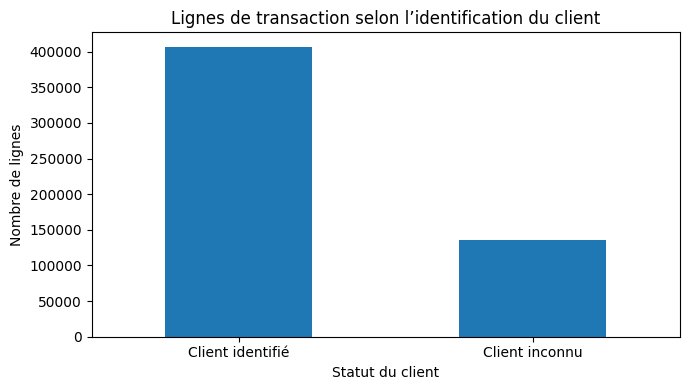

,Nombre de lignes
CustomerID,
Client identifié,406829
Client inconnu,135080


In [9]:
statut_client = df["CustomerID"].notna().map({
    True: "Client identifié",
    False: "Client inconnu"
}).value_counts()

plt.figure(figsize=(7, 4))
statut_client.plot(kind="bar")
plt.title("Lignes de transaction selon l’identification du client")
plt.xlabel("Statut du client")
plt.ylabel("Nombre de lignes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(statut_client.to_frame("Nombre de lignes"))

**9: BLOC CODE / MANIPULATION**

In [12]:
import pandas as pd

df = pd.read_excel("/kaggle/input/datasets/nisrineqacem/online-retail-xslx/Online Retail.xlsx")

print(df.shape)
print(df.columns.tolist())
print(df.head())

df.info()

print(df.isna().sum())

print(df.describe(include="all"))

(541909, 8)
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to

***OBSERVETION:***
 Le fichier contient 541 909 lignes et 8 colonnes. Des valeurs manquantes sont présentes dans les colonnes Description et CustomerID.

***INTERPRETATION:***
 Les données permettent d’analyser les ventes selon la date, les produits, les pays et les clients. Les valeurs manquantes constituent une limite de la source.

**10. ANALYSE ET INTERPRÉTATION**

***OBSERVATION***

Le fichier contient 541909 lignes et 8 colonnes. Il couvre la période du 01/12/2010 au 09/12/2011 et concerne 38 pays. Des valeurs manquantes existent dans CustomerID et Description. Des quantités négatives sont également présentes.

***ANALYSE***

Les champs permettent d'analyser les ventes par date, produit, pays et client. Les valeurs manquantes et négatives représentent des limites à prendre en compte.

***INTERPRÉTATION***

La source est exploitable pour le pilotage des ventes, mais certains éléments nécessitent une vérification métier.

***DÉCISION***

Retenir les quatre questions décisionnelles, inventorier les huit colonnes et documenter les limites de la source.

***11. DÉFI TECHNIQUE***

In [2]:
import pandas as pd

df = pd.read_excel(
    "/kaggle/input/datasets/nisrineqacem/online-retail-xslx/Online Retail.xlsx"
)

questions = {
    "Ventes dans le temps": ["InvoiceDate", "Quantity", "UnitPrice"],
    "Produits": ["StockCode", "Description", "Quantity", "UnitPrice"],
    "Pays": ["Country", "Quantity", "UnitPrice"],
    "Commandes et clients": ["InvoiceNo", "CustomerID"]
}

for question, champs in questions.items():
    if all(c in df.columns for c in champs):
        print("VALIDÉ :", question)
    else:
        print("À VÉRIFIER :", question)

VALIDÉ : Ventes dans le temps
VALIDÉ : Produits
VALIDÉ : Pays
VALIDÉ : Commandes et clients
